In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from sklearn.metrics import classification_report

In [ ]:
df = pd.read_csv("hospital_readmissions_30k.csv")

In [ ]:
print(df.head())
print(df.shape)
print(df.info())


   patient_id  age  gender blood_pressure  cholesterol   bmi diabetes  \
0           1   74   Other         130/72          240  31.5      Yes   
1           2   46  Female         120/92          292  36.3       No   
2           3   89   Other         135/78          153  30.3       No   
3           4   84  Female         123/80          153  31.5       No   
4           5   32   Other         135/84          205  18.4       No   

  hypertension  medication_count  length_of_stay discharge_destination  \
0           No                 5               1      Nursing_Facility   
1           No                 4               3      Nursing_Facility   
2          Yes                 1               1                  Home   
3          Yes                 3              10                  Home   
4          Yes                 6               4      Nursing_Facility   

  readmitted_30_days  
0                Yes  
1                 No  
2                 No  
3                 No  
4

In [ ]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate values:", df.duplicated().sum())


Missing values:
patient_id               0
age                      0
gender                   0
blood_pressure           0
cholesterol              0
bmi                      0
diabetes                 0
hypertension             0
medication_count         0
length_of_stay           0
discharge_destination    0
readmitted_30_days       0
dtype: int64
Duplicate values: 0


In [ ]:
df["systolic_bp"] = df["blood_pressure"].str.split("/").str[0].astype(float)
df["diastolic_bp"] = df["blood_pressure"].str.split("/").str[1].astype(float)



In [ ]:
df = df.drop(columns=["blood_pressure", "patient_id"])

df["readmitted_30_days"] = df["readmitted_30_days"].map({
    "No": 0,
    "Yes": 1
})

print(df.head())

   age  gender  cholesterol   bmi diabetes hypertension  medication_count  \
0   74   Other          240  31.5      Yes           No                 5   
1   46  Female          292  36.3       No           No                 4   
2   89   Other          153  30.3       No          Yes                 1   
3   84  Female          153  31.5       No          Yes                 3   
4   32   Other          205  18.4       No          Yes                 6   

   length_of_stay discharge_destination  readmitted_30_days  systolic_bp  \
0               1      Nursing_Facility                   1        130.0   
1               3      Nursing_Facility                   0        120.0   
2               1                  Home                   0        135.0   
3              10                  Home                   0        123.0   
4               4      Nursing_Facility                   0        135.0   

   diastolic_bp  
0          72.0  
1          92.0  
2          78.0  
3       

In [ ]:
df = pd.get_dummies(
    df,
    columns=[
        "gender",
        "diabetes",
        "hypertension",
        "discharge_destination"
    ],
    drop_first=True,
    dtype=int
)

print(df.head())
print(df.shape)

   age  cholesterol   bmi  medication_count  length_of_stay  \
0   74          240  31.5                 5               1   
1   46          292  36.3                 4               3   
2   89          153  30.3                 1               1   
3   84          153  31.5                 3              10   
4   32          205  18.4                 6               4   

   readmitted_30_days  systolic_bp  diastolic_bp  gender_Male  gender_Other  \
0                   1        130.0          72.0            0             1   
1                   0        120.0          92.0            0             0   
2                   0        135.0          78.0            0             1   
3                   0        123.0          80.0            0             0   
4                   0        135.0          84.0            0             1   

   diabetes_Yes  hypertension_Yes  discharge_destination_Nursing_Facility  \
0             1                 0                                    

In [ ]:
X = df.drop("readmitted_30_days", axis=1)
y = df["readmitted_30_days"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()


In [ ]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(
    penalty="l2",
    C=1.0,
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)



LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("ROC-AUC:", roc_auc)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Readmission", "Readmission"]
))

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

Accuracy: 0.8775
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.5638113327002215

Classification Report:
                precision    recall  f1-score   support

No Readmission       0.88      1.00      0.93      5265
   Readmission       0.00      0.00      0.00       735

      accuracy                           0.88      6000
     macro avg       0.44      0.50      0.47      6000
  weighted avg       0.77      0.88      0.82      6000


Confusion Matrix:
[[5265    0]
 [ 735    0]]


True Negatives: 5265
False Positives: 0
False Negatives: 735
True Positives: 0


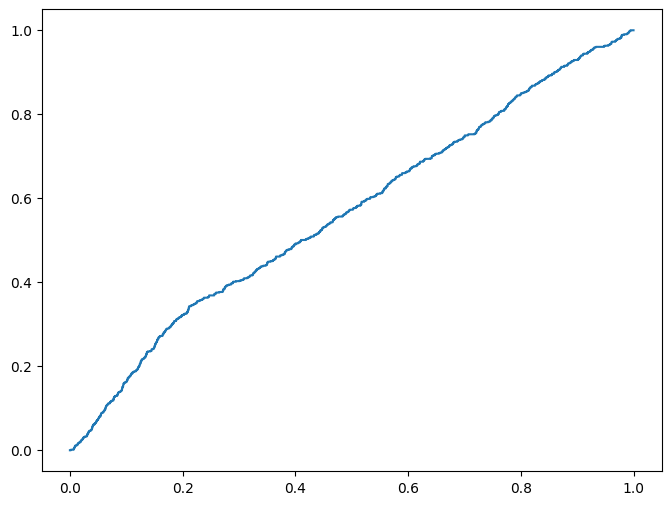

In [ ]:

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr,
    tpr,
    label="Logistic Regression (AUC = {:.3f})".format(roc_auc)
)





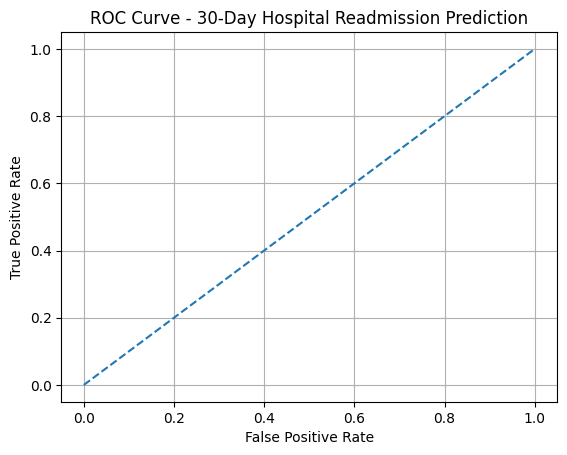

([<matplotlib.axis.YTick at 0x7863ebe94550>,
 [Text(0, 0, 'No Readmission'), Text(0, 1, 'Readmission')])

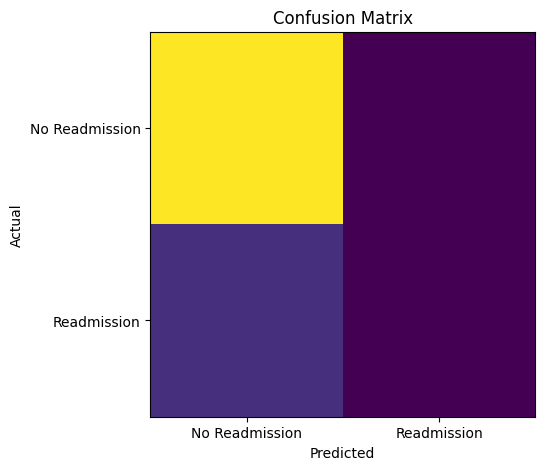

In [ ]:
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - 30-Day Hospital Readmission Prediction")

plt.grid()
plt.show()

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["No Readmission", "Readmission"])
plt.yticks([0, 1], ["No Readmission", "Readmission"])


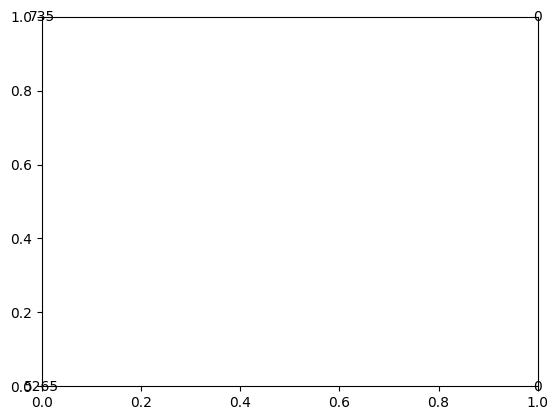

In [ ]:
for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.show()

In [ ]:
feature_names = X.columns
coefficients = model.coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Absolute_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

print("\nFeature Coefficients:")
print(feature_importance)

print("\nClinical Cost Analysis:")
print("False Negative:", fn)
print("False Positive:", fp)

print("\nA false negative means that a patient who is actually readmitted within 30 days is predicted as not readmitted.")
print("A false positive means that a patient who is not readmitted within 30 days is predicted as being at risk.")

print("\nIn clinical settings, false negatives can be more costly because a high-risk patient may not receive additional monitoring or intervention.")
print("False positives may lead to additional monitoring, follow-up, or use of healthcare resources.")

print("\nFinal ROC-AUC:", roc_auc)


Feature Coefficients:
                                   Feature  Coefficient  Absolute_Coefficient
12             discharge_destination_Rehab     0.274519              0.274519
11  discharge_destination_Nursing_Facility     0.184903              0.184903
9                             diabetes_Yes     0.082126              0.082126
10                        hypertension_Yes     0.076297              0.076297
2                                      bmi    -0.042183              0.042183
1                              cholesterol     0.025385              0.025385
5                              systolic_bp    -0.017891              0.017891
8                             gender_Other     0.010008              0.010008
4                           length_of_stay    -0.009069              0.009069
3                         medication_count     0.008023              0.008023
0                                      age     0.007423              0.007423
7                              gender_Mal